In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("retail_sales_dataset.csv")
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


## STEP 1: Inspect the data

In [2]:
print("Rows, columns:", df.shape)
print()
df.info()

Rows, columns: (1000, 9)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [3]:
print("Nulls per column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Nulls per column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows: 0


## Step 2: Descriptive statistics

In [4]:
num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
df[num_cols].describe()

,Age,Quantity,Price per Unit,Total Amount
count,1000.00000,1000.000000,1000.000000,1000.000000
mean,41.39200,2.514000,179.890000,456.000000
std,13.68143,1.132734,189.681356,559.997632
min,18.00000,1.000000,25.000000,25.000000
25%,29.00000,1.000000,30.000000,60.000000
50%,42.00000,3.000000,50.000000,135.000000
75%,53.00000,4.000000,300.000000,900.000000
max,64.00000,4.000000,500.000000,2000.000000


In [5]:
stats = pd.DataFrame({
    "mean": df[num_cols].mean(),
    "median": df[num_cols].median(),
    "mode": df[num_cols].mode().iloc[0],
    "std": df[num_cols].std()
})
stats.round(2)

,mean,median,mode,std
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00


## Step 3: Fix the Date column

In [6]:
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.month
df["Quarter"] = df["Date"].dt.quarter
df["DayOfWeek"] = df["Date"].dt.day_name()
df.dtypes

Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
Month                        int32
Quarter                      int32
DayOfWeek                   object
dtype: object

## Initial Inspection and Descriptive Statistics
The dataset has 1,000 transactions and 9 columns, with no missing values or duplicates.
Customer age is roughly symmetric (mean 41.4, median 42), so there is no strong skew.
Price per Unit and Total Amount are right-skewed: the mean (179.9 and 456) is far above the
median (50 and 135). Most purchases are low-value, but a small number of high-priced
transactions contribute a large share of total revenue.

## Time series (monthly and quarterly sales)

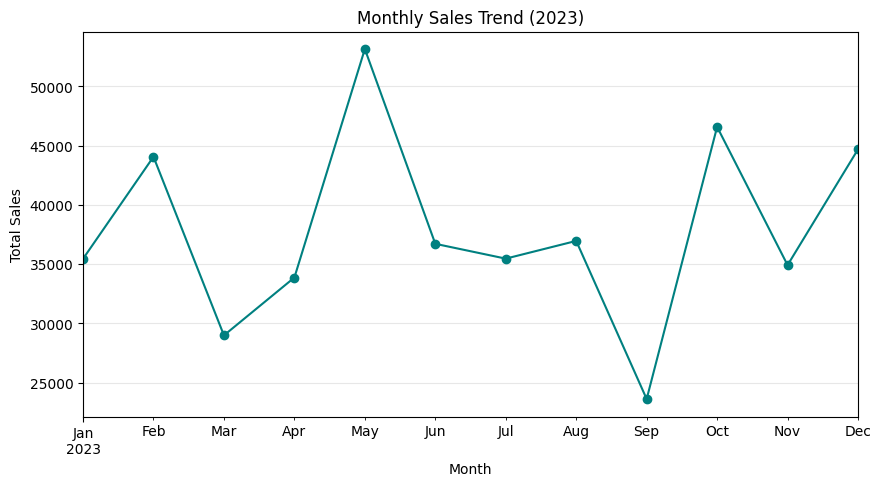

In [7]:
#monthly sales
monthly = df.set_index("Date").resample("ME")["Total Amount"].sum()
monthly = monthly[monthly.index < "2024-01-01"]   # drop partial Jan 2024

plt.figure(figsize=(10,5))
monthly.plot(marker="o", color="teal")
plt.title("Monthly Sales Trend (2023)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(alpha=0.3)
plt.show()

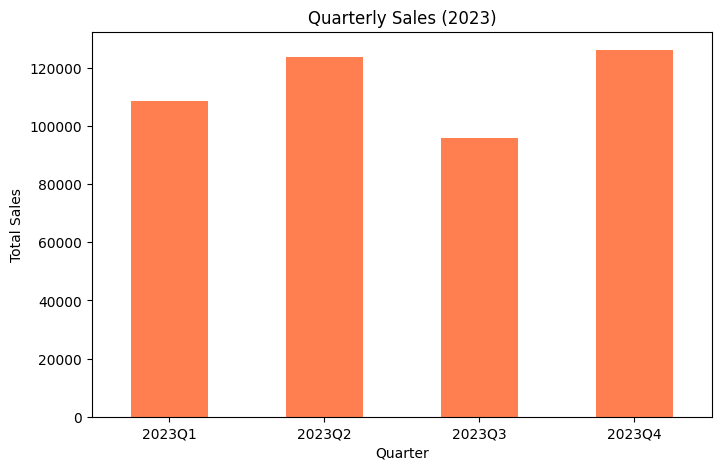

In [8]:
#Quaterly sales
quarterly = df.set_index("Date").resample("QE")["Total Amount"].sum()
quarterly = quarterly[quarterly.index < "2024-01-01"]
quarterly.index = quarterly.index.to_period("Q").astype(str)   # this line makes the clean labels

plt.figure(figsize=(8,5))
quarterly.plot(kind="bar", color="coral")
plt.title("Quarterly Sales (2023)")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()

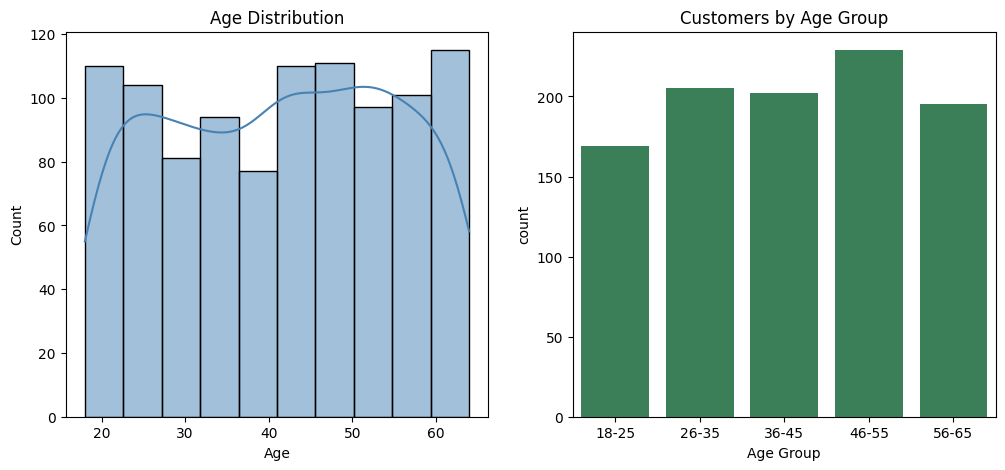

Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56-65    195
Name: count, dtype: int64


In [9]:
bins = [17, 25, 35, 45, 55, 65]
labels = ["18-25", "26-35", "36-45", "46-55", "56-65"]
df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels)

fig, ax = plt.subplots(1, 2, figsize=(12,5))
sns.histplot(df["Age"], bins=10, kde=True, color="steelblue", ax=ax[0])
ax[0].set_title("Age Distribution")
sns.countplot(x="Age Group", data=df, color="seagreen", ax=ax[1])
ax[1].set_title("Customers by Age Group")
plt.show()

print(df["Age Group"].value_counts().sort_index())

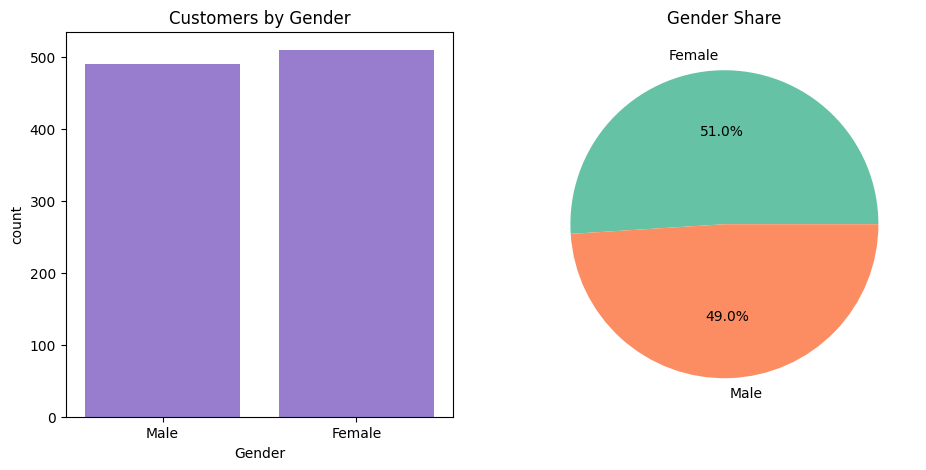

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11,5))
sns.countplot(x="Gender", data=df, color="mediumpurple", ax=ax[0])
ax[0].set_title("Customers by Gender")
df["Gender"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=ax[1],
                                 colors=["#66c2a5","#fc8d62"])
ax[1].set_ylabel("")
ax[1].set_title("Gender Share")
plt.show()

In [11]:
print(df.groupby("Age Group", observed=True)["Total Amount"].sum())
print()
print(df.groupby("Gender")["Total Amount"].agg(["sum", "mean"]).round(2))

Age Group
18-25     84550
26-35     98480
36-45     91870
46-55    100690
56-65     80410
Name: Total Amount, dtype: int64

           sum    mean
Gender                
Female  232840  456.55
Male    223160  455.43


## Customer Demographics

**Age:** Customers are spread fairly evenly from 18 to 64, with no single age dominating. The histogram has small dips around ages 30 and 40, but nothing large.

| Age group | Customers |
|---|---|
| 18-25 | 169 |
| 26-35 | 205 |
| 36-45 | 202 |
| 46-55 | 229 |
| 56-65 | 195 |

The 46-55 group is the largest (229 customers) and 18-25 is the smallest (169). The 18-25 group covers only 8 years while the others cover 10, which partly explains why it is smaller.

**Gender:** The customer base is almost perfectly balanced: 510 female (51%) and 490 male (49%). With a split this even, gender is unlikely to explain differences in sales volume.

**Note on "top 10 products":** The checklist asks for the top 10 best-selling products, but this dataset has no product names, only three categories (Electronics, Clothing and Beauty). So I ranked the best sellers at the category level and also listed the 10 largest individual transactions.

In [12]:
g = df.groupby("Age Group", observed=True)["Total Amount"].agg(["count", "sum", "mean"]).round(2)
g.columns = ["Customers", "Revenue", "Avg per Transaction"]
g

,Customers,Revenue,Avg per Transaction
Age Group,,,
18-25,169,84550,500.30
26-35,205,98480,480.39
36-45,202,91870,454.80
46-55,229,100690,439.69
56-65,195,80410,412.36


## Spending by Age and Gender

| Age group | Customers | Revenue | Avg per transaction |
|---|---|---|---|
| 18-25 | 169 | 84,550 | ~500 |
| 26-35 | 205 | 98,480 | ~480 |
| 36-45 | 202 | 91,870 | ~455 |
| 46-55 | 229 | 100,690 | ~440 |
| 56-65 | 195 | 80,410 | ~412 |

**Age:** The 46-55 group brings in the most revenue (~100.7K, about 22% of the total), mainly because it is the largest group. But the average spend per transaction goes down as age goes up. The 18-25 group is the smallest, yet spends the most per transaction (~500), while 56-65 spends the least (~412). This difference is small, though. The correlation between age and spending was only about -0.06, so age is a weak factor on its own.

**Gender:** Female customers generate slightly more revenue (232,840 vs 223,160), but the average transaction is almost the same (~456.55 vs ~455.43). The revenue gap exists because there are 20 more female customers (510 vs 490), not because women spend more.

                  Revenue  Units  Transactions  AvgPrice
Product Category                                        
Electronics        156905    849           342    181.90
Clothing           155580    894           351    174.29
Beauty             143515    771           307    184.06


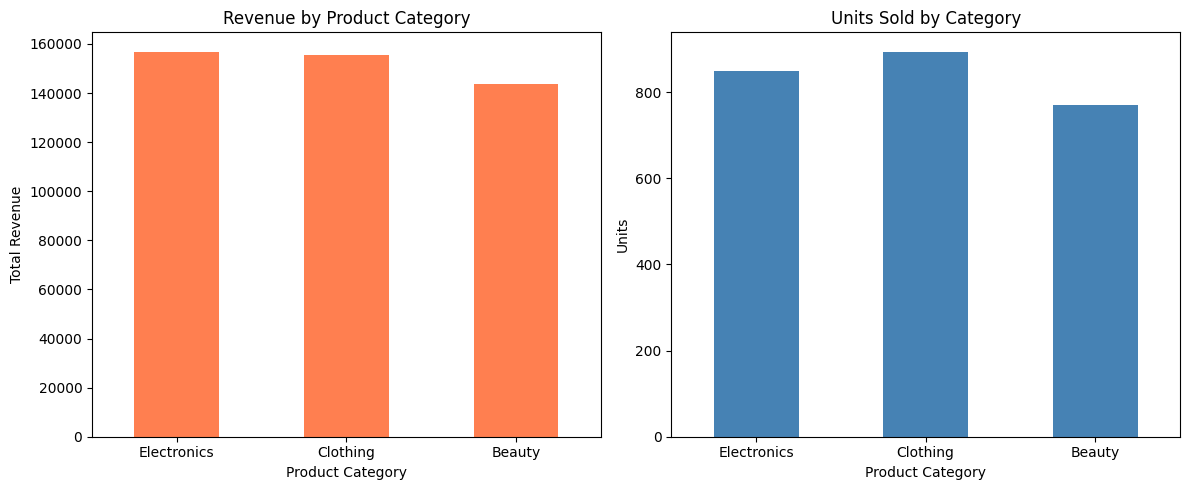

In [13]:
cat = df.groupby("Product Category").agg(
    Revenue=("Total Amount", "sum"),
    Units=("Quantity", "sum"),
    Transactions=("Transaction ID", "count"),
    AvgPrice=("Price per Unit", "mean")
).sort_values("Revenue", ascending=False).round(2)
print(cat)

fig, ax = plt.subplots(1, 2, figsize=(12,5))
cat["Revenue"].plot(kind="bar", color="coral", ax=ax[0])
ax[0].set_title("Revenue by Product Category")
ax[0].set_ylabel("Total Revenue")
ax[0].tick_params(axis="x", rotation=0)
cat["Units"].plot(kind="bar", color="steelblue", ax=ax[1])
ax[1].set_title("Units Sold by Category")
ax[1].set_ylabel("Units")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [14]:
df.nlargest(10, "Total Amount")[["Transaction ID", "Date", "Product Category", "Quantity", "Price per Unit", "Total Amount"]]

,Transaction ID,Date,Product Category,Quantity,Price per Unit,Total Amount
14,15,2023-01-16,Electronics,4,500,2000
64,65,2023-12-05,Electronics,4,500,2000
71,72,2023-05-23,Electronics,4,500,2000
73,74,2023-11-22,Beauty,4,500,2000
88,89,2023-10-01,Electronics,4,500,2000
92,93,2023-07-14,Beauty,4,500,2000
108,109,2023-10-18,Electronics,4,500,2000
117,118,2023-05-16,Electronics,4,500,2000
123,124,2023-10-27,Clothing,4,500,2000
138,139,2023-12-15,Beauty,4,500,2000


In [15]:
print((df["Total Amount"] == 2000).sum(), "transactions at the 2000 maximum")
print(df["Price per Unit"].value_counts().sort_index())

49 transactions at the 2000 maximum
Price per Unit
25     210
30     183
50     211
300    197
500    199
Name: count, dtype: int64


In [16]:
df["Price Tier"] = np.where(df["Price per Unit"] >= 300, "High (300-500)", "Low (25-50)")
tier = df.groupby("Price Tier")["Total Amount"].agg(["count", "sum"])
tier["Revenue Share %"] = (tier["sum"] / tier["sum"].sum() * 100).round(1)
tier

,count,sum,Revenue Share %
Price Tier,,,
High (300-500),396,402900,88.4
Low (25-50),604,53100,11.6


## Price Distribution

Price per Unit only takes five values: 25, 30, 50, 300 and 500. I grouped them into a low-price tier (25-50) and a high-price tier (300-500).

| Tier | Transactions | Revenue | Share of revenue |
|---|---|---|---|
| High (300-500) | 396 | 402,900 | 88.4% |
| Low (25-50) | 604 | 53,100 | 11.6% |

Transactions are spread fairly evenly across the five prices (about 18-21% each), but the high-price tier makes up only about 40% of sales and brings in 88.4% of the revenue. A typical high-price sale is worth about 1,017, compared to about 88 for a low-price sale.

This explains why the mean transaction value (456) is so much higher than the median (135): a minority of expensive purchases pulls the average up.

Also, 49 transactions reached the maximum possible value of 2,000 (4 units at a price of 500).

## Product Category Analysis

**Note:** This dataset only has product categories, not individual product names, so I could not do a "top 10 products" analysis. I did it at the category level instead, and also looked at the 10 largest transactions.

**Revenue by category:**
- Electronics: ~156.9K (highest)
- Clothing: ~155.6K
- Beauty: ~143.5K (about 9% lower than Electronics)

Electronics and Clothing are almost tied, so no single category dominates the business.

**Units and prices:** Clothing sells the most units (894) but earns slightly less than Electronics, which means Electronics makes more money per unit sold. Beauty sells the fewest units (771) and has the lowest revenue, even though its average price per unit is the highest (~184). The price differences between categories are small, so the gap comes mainly from volume.

**Top 10 transactions:** All ten are exactly 2,000 (4 units at a price of 500). This is the maximum possible transaction in this dataset, so they show the biggest basket size and are not a real ranking. In total, 49 transactions reached this maximum.

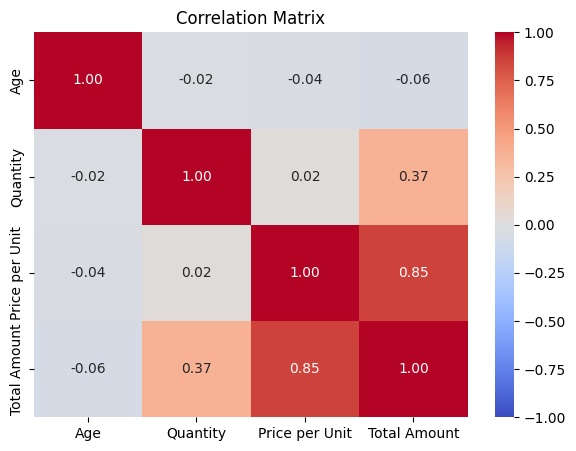

In [17]:
corr_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
plt.figure(figsize=(7,5))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

## Correlation Analysis

The strongest relationship in the heatmap is between Total Amount and Price per Unit (0.85). Quantity is also related to Total Amount, but less (0.37). This is expected because Total Amount is calculated as Quantity × Price per Unit, so it isn't a real discovery.

The more useful result is what is NOT related:
- Age has almost no correlation with Quantity, Price per Unit or Total Amount (between -0.02 and -0.06), so age alone does not predict how much someone spends.
- Quantity and Price per Unit are unrelated (0.02), so customers don't buy more units of cheaper items.

The price a customer chooses matters much more than how many units they buy. The small differences in spending between age groups seen earlier are weak effects.

## Additional Insight: Age, Category and Day of Week

**Day of week:** Saturday brings in the most revenue (~79K) and Thursday the least (~54K). Sales are fairly strong on Monday and Tuesday, drop on Wednesday and Thursday, then rise again towards the weekend. Sunday is lower than I expected (~58K). Each day has only about 140 transactions, so some of this difference could be chance.

**Age and category:** Earlier, the correlation between age and spending was almost zero (about -0.06), so it looked like age didn't matter. The heatmap shows a different picture once I split by category:
- Customers aged 26-35 spend the most on Clothing (540 per transaction).
- Customers aged 56-65 spend the most on Electronics (507) but the least on Beauty (325).
- Customers aged 18-25 spend a similar, high amount on Beauty and Clothing (about 520).

So the overall average hides differences between age and category combinations. Each heatmap cell has only about 50-80 transactions and the data is synthetic, so I treat these as patterns worth testing, not proven facts.

## Conclusion and Business Recommendations

### Key Findings
- Total sales in 2023 were about 456K. Sales went up and down through the year with no steady growth. May was the best month (~53K) and September was the worst (~23.5K).
- The biggest finding is the price split. Only about 40% of transactions (396 sales at a price of 300 or 500) bring in 88.4% of the revenue. A high-price sale averages about 1,017, compared to about 88 for a low-price sale.
- Electronics, Clothing and Beauty earn similar revenue, and customers are spread evenly across ages and genders. Age on its own does not predict spending (correlation about -0.06), but age combined with category does show differences.

### Recommendations
1. **Focus on high-price products.** Since high-price items give most of the revenue, it makes sense to keep them well stocked and promote them. One idea to test is offering bundles that encourage low-price buyers to move up to a higher-priced item.

2. **Match categories to age groups.** Customers aged 26-35 spend the most on Clothing (540 per transaction), and customers aged 18-25 spend about 520 on both Beauty and Clothing. So Clothing and Beauty offers could be aimed at under-35s. Customers aged 56-65 spend the most on Electronics (507) and the least on Beauty (325), so Electronics is a better priority for them.

3. **Use the slow days and months.** Saturday is the best day (~79K) and Thursday is the weakest (~54K), so a mid-week offer could help. September was also the weakest month, and Q4 was the strongest quarter (~126K). If this pattern repeats in other years, extra stock and promotions around Q4 could pay off, but one year of data is not enough to confirm seasonality.

### Limitations
This is a synthetic dataset covering one year, and some age and category groups have only 50-80 transactions. These patterns should be checked on real data before making big business decisions.